# Geometry-Aware Quantum Cloud Challenge — Submission

**Team:** TODO  
**Members:** TODO  
**Repository / commit:** TODO

Complete Levels 1–3 for all three official processor models. Read the challenge brief and practice tutorial first. Load the shared inputs from `challenge_config.py`; keep the official benchmark separate from optional studies. All solution code and results are yours to supply.

Success means a reproducible comparison of routing and protection tradeoffs across all nine cases. Protection need not improve fidelity, and the hyperbolic model need not win. Explain negative results using your measured costs, uncertainty and yield. All required runs are local simulations; no IBM account or QPU access is needed.


## Setup and reproducibility

Record package versions, simulator and transpiler seeds, shots **per basis**, bootstrap settings, optimization level, layout and routing settings. Use independent simulator seeds for XX, YY and ZZ. Explain any differences in compilation between models. Start Jupyter from this repository with `uv run jupyter lab challenge_submission.ipynb`.


In [ ]:
import platform
from importlib.metadata import version

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from qiskit import QuantumCircuit, transpile
from qiskit.transpiler.passes import RemoveBarriers
from qiskit_aer import AerSimulator

from challenge_config import (
    BOOTSTRAP_RESAMPLES, CASES, CONFIDENCE_LEVEL, CONFIG_VERSION, PROCESSORS,
    SEED, SHOTS_PER_BASIS, SYNTHETIC_BASIS_GATES, get_ibm_backend, make_noise_model,
)

BASIS_ORDER = ("XX", "YY", "ZZ")
LEVEL2_CASES = tuple(case for case in CASES if case[2] == 2)
SIMULATOR_METHOD = "matrix_product_state"
OPTIMIZATION_LEVEL = 0
SIMULATOR_OPTIONS = {
    "reference_2016": {},
    "ibm_today": {"max_parallel_threads": 1, "max_parallel_experiments": 1,
                  "matrix_product_state_truncation_threshold": 1e-16,
                  "mps_sample_measure_algorithm": "mps_apply_measure"},
    "hyperbolic": {"max_parallel_threads": 1},
}

# MPS stores the 35-qubit state as a chain of smaller tensors.
# Record its sampling options alongside the seeds for repeatability.
run_settings = {
    "Configuration version": CONFIG_VERSION,
    "Cases": [case_number for case_number, _, _ in LEVEL2_CASES],
    "Noise": "official Level 2 model",
    "Simulator method": SIMULATOR_METHOD, "Simulator options": SIMULATOR_OPTIONS,
    "Shots per basis": SHOTS_PER_BASIS, "Base seed": SEED,
    "Simulator seed rule": "base + 100 * case + basis index (XX=0, YY=1, ZZ=2)",
    "Transpiler seed": SEED, "Optimization level": OPTIMIZATION_LEVEL,
    "Layout": "identity physical layout", "Routing": "explicit SWAPs; automatic routing off",
    "Bootstrap resamples": BOOTSTRAP_RESAMPLES, "Confidence level": CONFIDENCE_LEVEL,
    "Bootstrap seed rule": "base + 100 * case + 10",
}
display(pd.Series(run_settings, name="Value").to_frame())
display(pd.DataFrame([
    {"Package": "Python", "Version": platform.python_version()},
    *({"Package": package, "Version": version(package)} for package in
      ("qiskit", "qiskit-aer", "qiskit-ibm-runtime", "numpy", "networkx", "pandas", "matplotlib")),
]))

# Load IBM FakeGuadalupeV2 backend
ibm_backend = get_ibm_backend()
ibm_backend_record = {
    "Backend": ibm_backend.name,
    "Class": f"{type(ibm_backend).__module__}.{type(ibm_backend).__name__}",
    "Snapshot update": str(ibm_backend.properties().last_update_date),
    "Target operations": sorted(ibm_backend.operation_names),
}
display(pd.Series(ibm_backend_record, name="Value").to_frame())

,Value
Configuration version,1.0
Cases,"[2, 5, 8]"
Noise,official Level 2 model
Simulator method,matrix_product_state
Simulator options,"{'reference_2016': {}, 'ibm_today': {'max_para..."
Shots per basis,8192
Base seed,2026
Simulator seed rule,"base + 100 * case + basis index (XX=0, YY=1, Z..."
Transpiler seed,2026
Optimization level,0


,Package,Version
0,Python,3.12.15
1,qiskit,2.4.1
2,qiskit-aer,0.17.2
3,qiskit-ibm-runtime,0.51.0
4,numpy,2.5.4
5,networkx,3.7
6,pandas,3.1.0
7,matplotlib,3.11.2


,Value
Backend,fake_guadalupe
Class,qiskit_ibm_runtime.fake_provider.backends.guad...
Snapshot update,2021-04-20 07:26:31+02:00
Target operations,"[cx, delay, id, measure, reset, rz, sx, x]"


## Official graphs and ports

Draw all three coupling graphs, label physical qubits and highlight each fixed port pair. State the noise model and native gates for each processor. For the IBM model, record the exact fake backend and package version. Explain how the final physical locations of the Bell pair will be verified.

Use `challenge_config.PROCESSORS` for the three specs (`edges`, `ports`, `num_qubits`, `coupling_map()`), `CASES` for case numbering, and `get_ibm_backend()` / `make_noise_model(processor_id)` for the fixed backend and noise. See the README for gate bases and sampling defaults. The IBM snapshot is bundled with `qiskit-ibm-runtime==0.51.0`; do not refresh it.


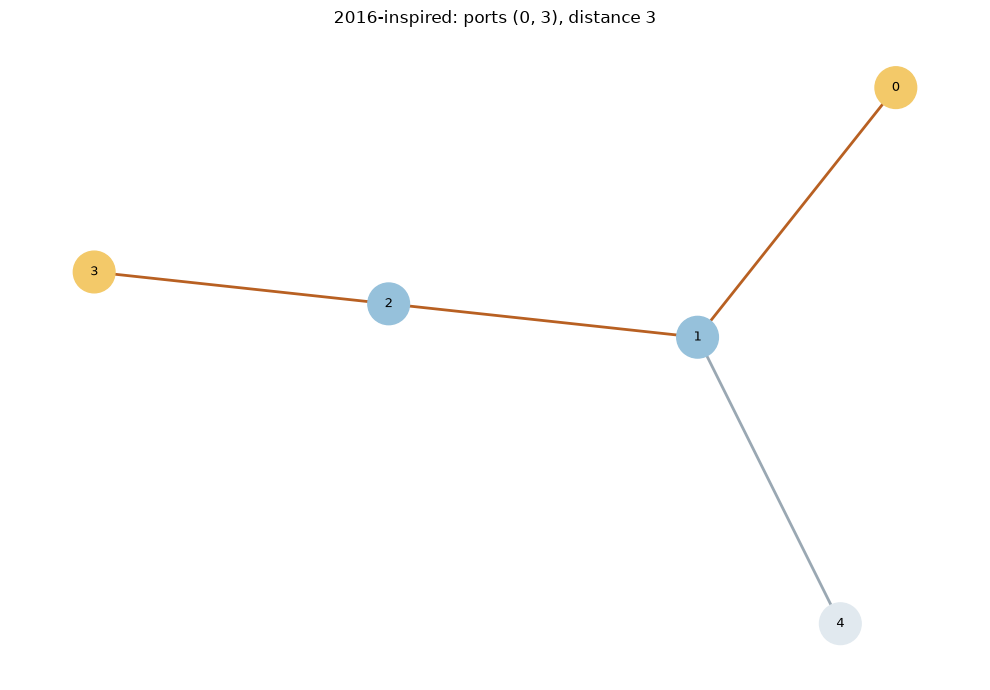

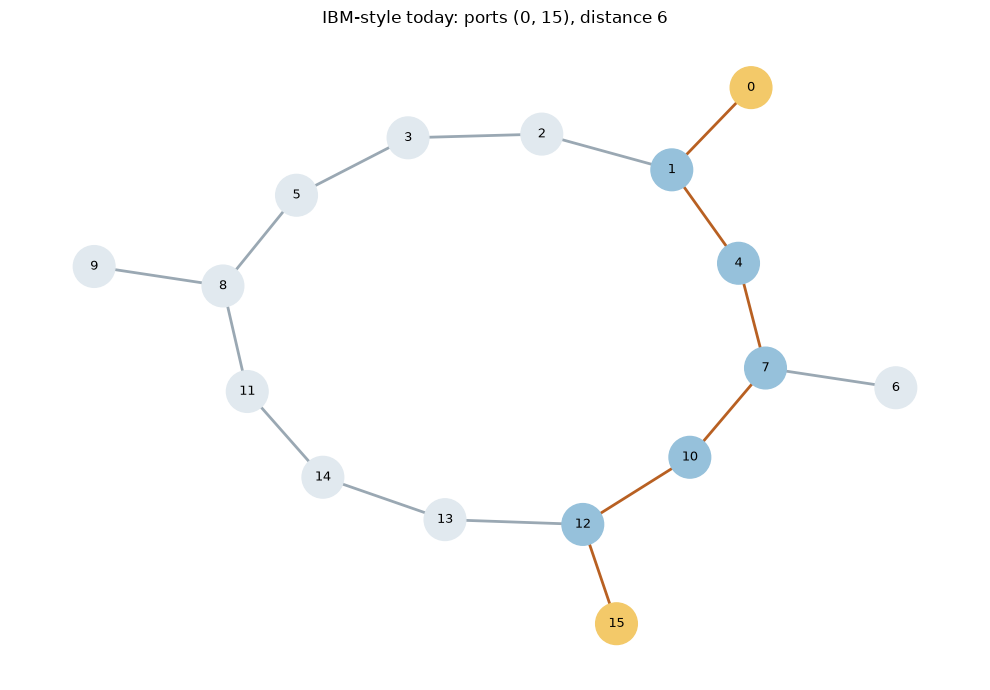

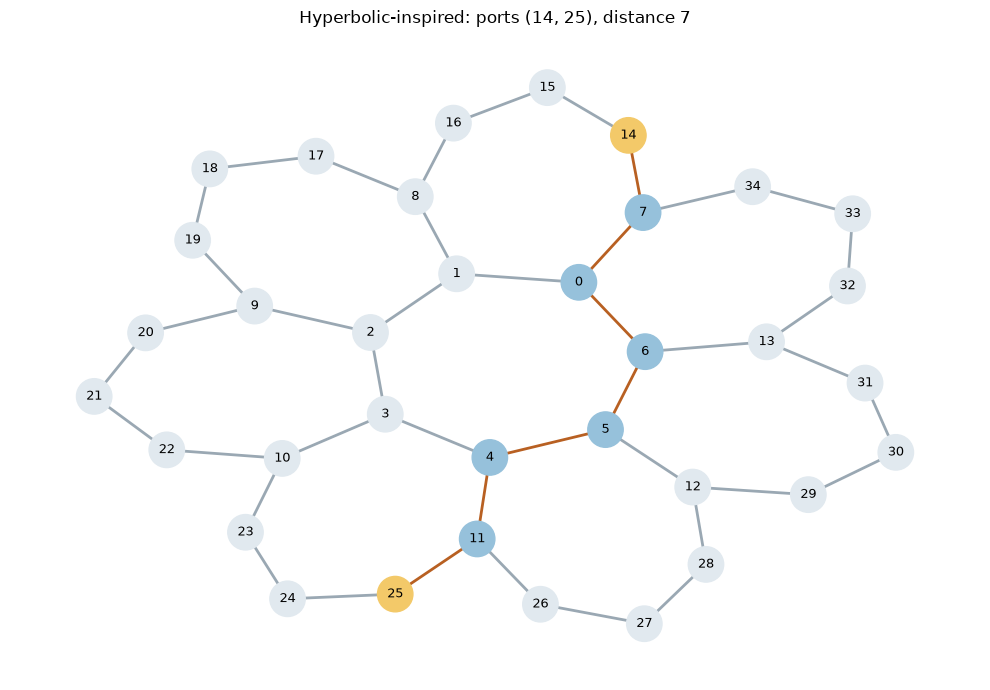

,Processor,Physical ports,Physical qubits,Undirected edges,Route,Port distance
0,reference_2016,"(0, 3)",5,4,"[0, 1, 2, 3]",3
1,ibm_today,"(0, 15)",16,16,"[0, 1, 4, 7, 10, 12, 15]",6
2,hyperbolic,"(14, 25)",35,42,"[14, 7, 0, 6, 5, 4, 11, 25]",7


In [2]:
processor_graphs, processor_routes = {}, {}
graph_rows = []
for model_id, model in PROCESSORS.items():
    graph = nx.Graph()
    graph.add_nodes_from(range(model.num_qubits))
    graph.add_edges_from(model.edges)

    # Draw each bidirectional coupling as one connection between physical qubits.
    # Choose a path with the fewest edges between the fixed ports.
    route = nx.shortest_path(graph, *model.ports)
    processor_graphs[model_id] = graph
    processor_routes[model_id] = route
    graph_rows.append({
        "Processor": model_id, "Physical ports": model.ports,
        "Physical qubits": model.num_qubits, "Undirected edges": graph.number_of_edges(),
        "Route": route, "Port distance": len(route) - 1,
    })
    node_colors = ["#f3c969" if qubit in model.ports else
                   "#96c1db" if qubit in route else "#e1e9ef" for qubit in graph.nodes]
    route_edges = {frozenset(edge) for edge in zip(route, route[1:])}
    edge_colors = ["#b86022" if frozenset(edge) in route_edges else "#9aa8b3"
                   for edge in graph.edges]
    figure, axis = plt.subplots(figsize=(10, 7))
    nx.draw_networkx(
        graph, pos=nx.kamada_kawai_layout(graph), node_color=node_colors,
        edge_color=edge_colors, node_size=650 if model.num_qubits > 20 else 900,
        font_size=9, width=2, ax=axis,
    )
    axis.set_title(f"{model.name}: ports {model.ports}, distance {len(route) - 1}")
    axis.set_axis_off()
    figure.tight_layout()
    display(figure)
    plt.close(figure)

display(pd.DataFrame(graph_rows))

## Level 1 — Make it: an ideal Bell pair

**Cases 1, 4, 7:** 2016-inspired, IBM-style today, hyperbolic-inspired.

Prepare the target Bell state on each model's two fixed ports. Compile for the relevant connectivity and gate set, verify the final physical locations, and draw the transpiled circuits. Measure XX, YY and ZZ without noise and estimate Bell fidelity. Record depth, two-qubit gates, SWAPs before decomposition, and physical qubits actually used. Follow the README common reporting conventions: the table uses the complete ZZ circuit, depth includes measurements with barriers excluded, and two-qubit gates are counted after native-gate decomposition. Preserve the routed circuit to count SWAPs before decomposition. Report XX and YY costs, including their basis rotations, separately.


In [ ]:
# TODO: Write your solution here.


## Level 2 — Break it: add noise

**Cases 2, 5, 8:** use each model's official noise assumptions on the Level 1 circuits. Ensure compiled gate names match the noise model, including the IBM backend's native gates.

Report fidelity and a 95% bootstrap confidence interval, resampling each basis independently before combining correlators. Plot fidelity against two-qubit gate count and SWAP overhead. Explain connectivity costs separately from gate-set and noise differences.


In [3]:
def level2_measurement_circuit(model_id, basis):
    if basis not in BASIS_ORDER:
        raise ValueError(f"Unsupported Bell measurement basis: {basis}")
    model = PROCESSORS[model_id]
    route = processor_routes[model_id]
    circuit = QuantumCircuit(model.num_qubits, 2, name=f"{model_id}_{basis}")
    circuit.h(route[0])
    circuit.cx(route[0], route[1])

    # The first Bell half stays at route[0].
    # Successive SWAPs carry the other half to the second port at route[-1].
    for left, right in zip(route[1:-1], route[2:]):
        circuit.swap(left, right)
    for port in model.ports:
        if basis == "YY":
            # Sdg then H converts a Z readout into a Y measurement.
            circuit.sdg(port)
        if basis in ("XX", "YY"):
            circuit.h(port)
    circuit.measure(list(model.ports), [0, 1])
    return circuit


def verify_level2_circuit(circuit, model_id):
    model = PROCESSORS[model_id]
    allowed = (set(ibm_backend.operation_names) if model_id == "ibm_today" else
               set(SYNTHETIC_BASIS_GATES) | {"measure"})
    measurements = {}
    for instruction in circuit.data:
        name = instruction.operation.name
        assert name in allowed, name
        assert name not in {"reset", "delay"}, name
        if len(instruction.qubits) == 2:
            edge = tuple(circuit.find_bit(qubit).index for qubit in instruction.qubits)
            assert edge in model.edges, edge
        if name == "measure":
            measurements[circuit.find_bit(instruction.clbits[0]).index] = (
                circuit.find_bit(instruction.qubits[0]).index
            )
    assert measurements == {0: model.ports[0], 1: model.ports[1]}, measurements
    return measurements

2016-inspired XX compiled circuit


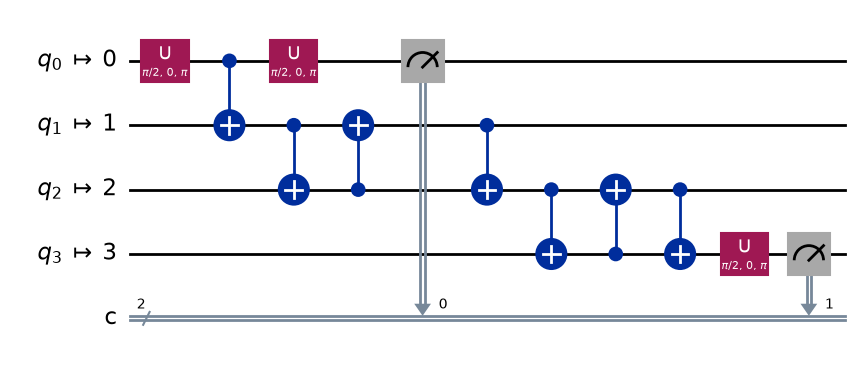

2016-inspired YY compiled circuit


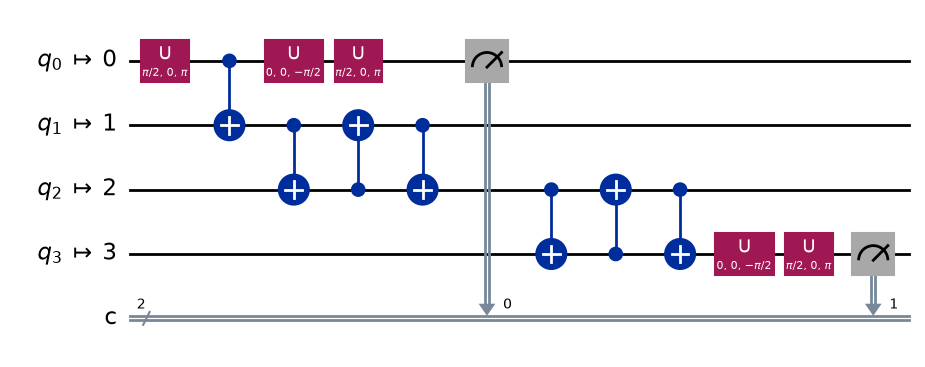

2016-inspired ZZ compiled circuit


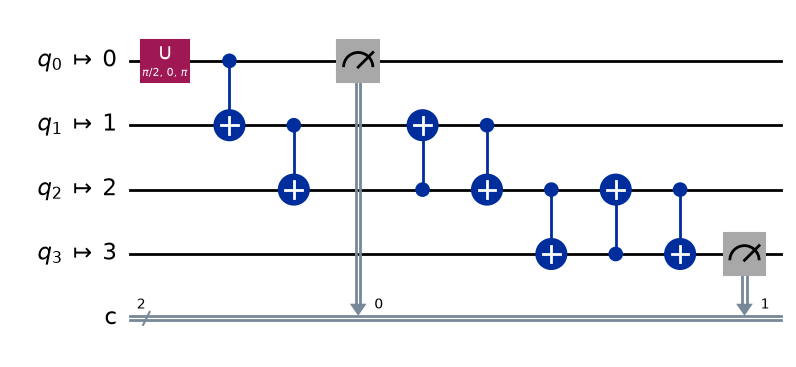

IBM-style today XX compiled circuit


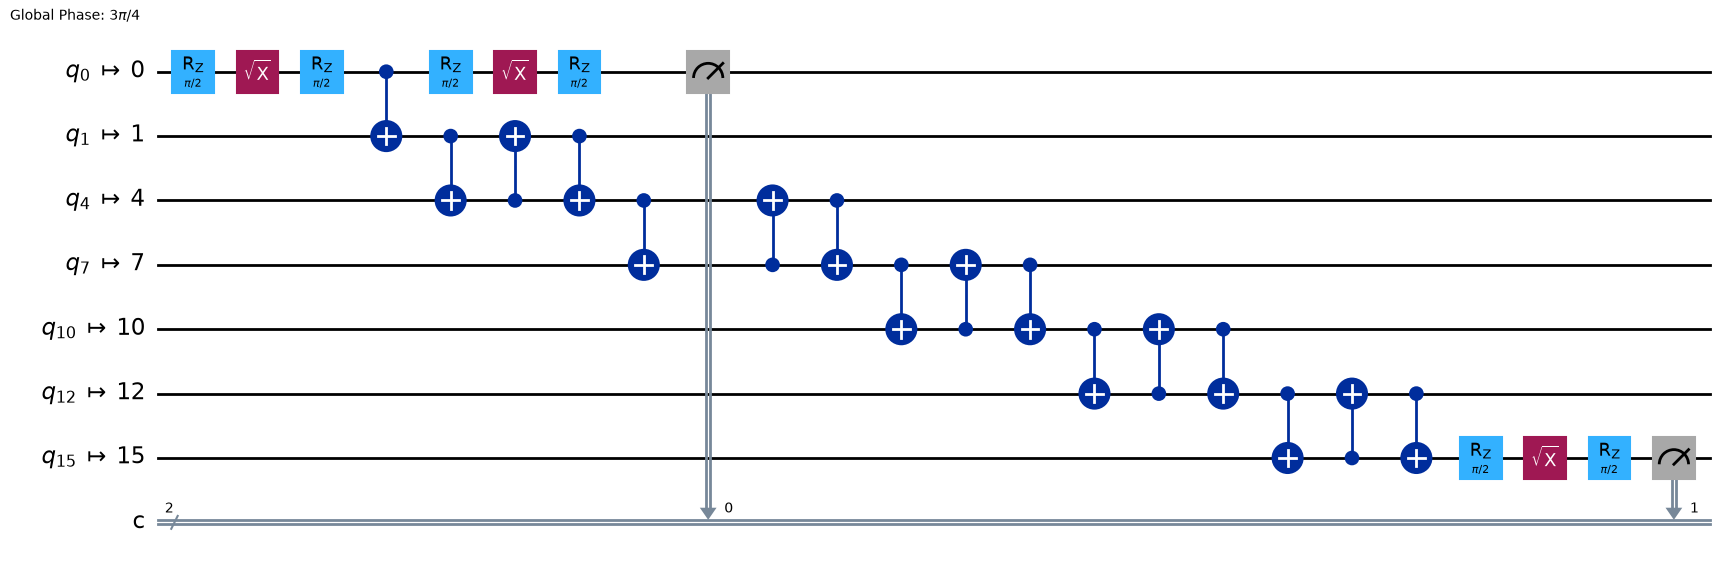

IBM-style today YY compiled circuit


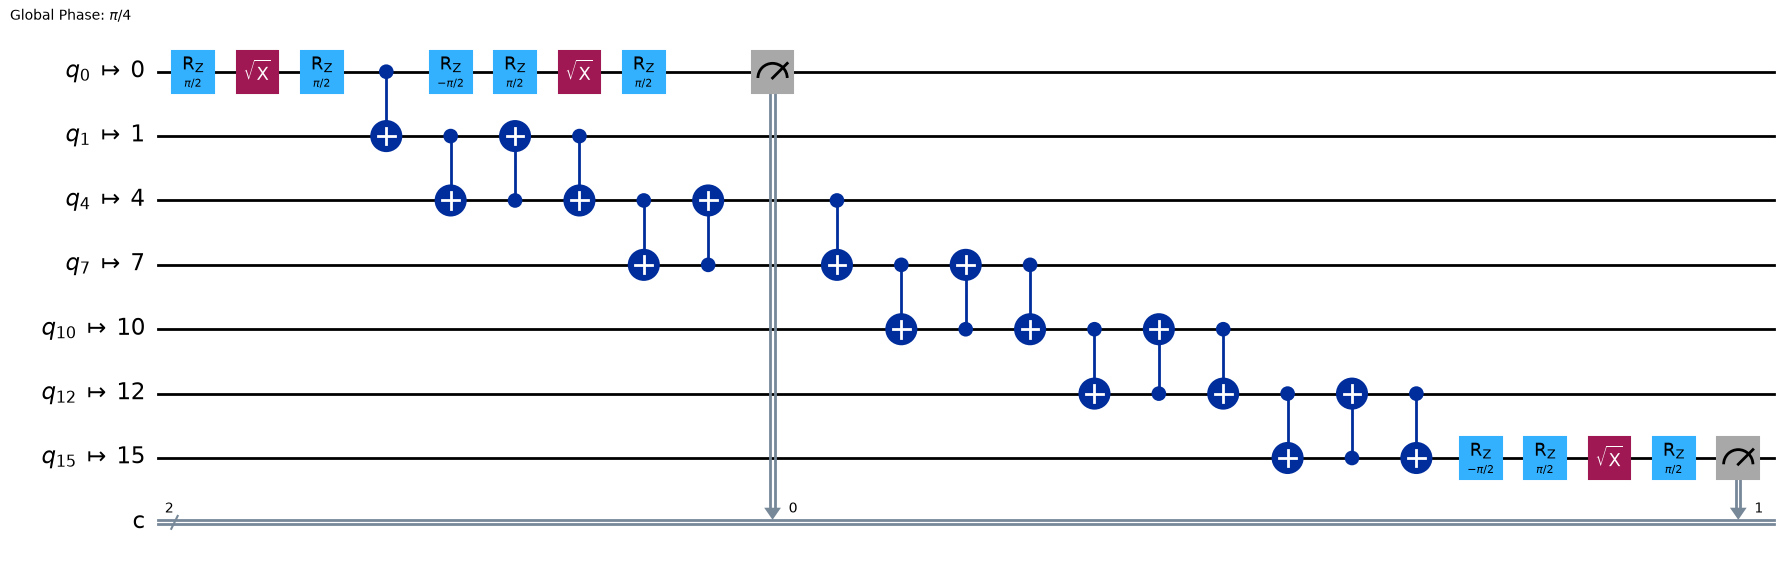

IBM-style today ZZ compiled circuit


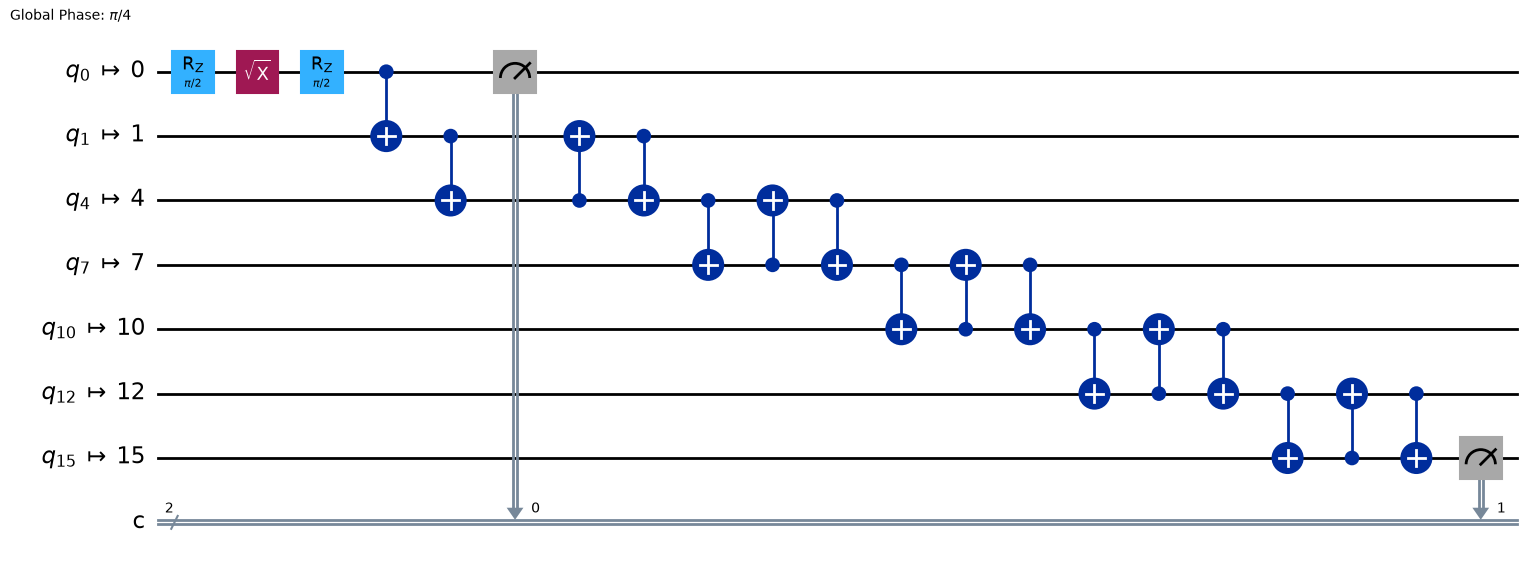

Hyperbolic-inspired XX compiled circuit


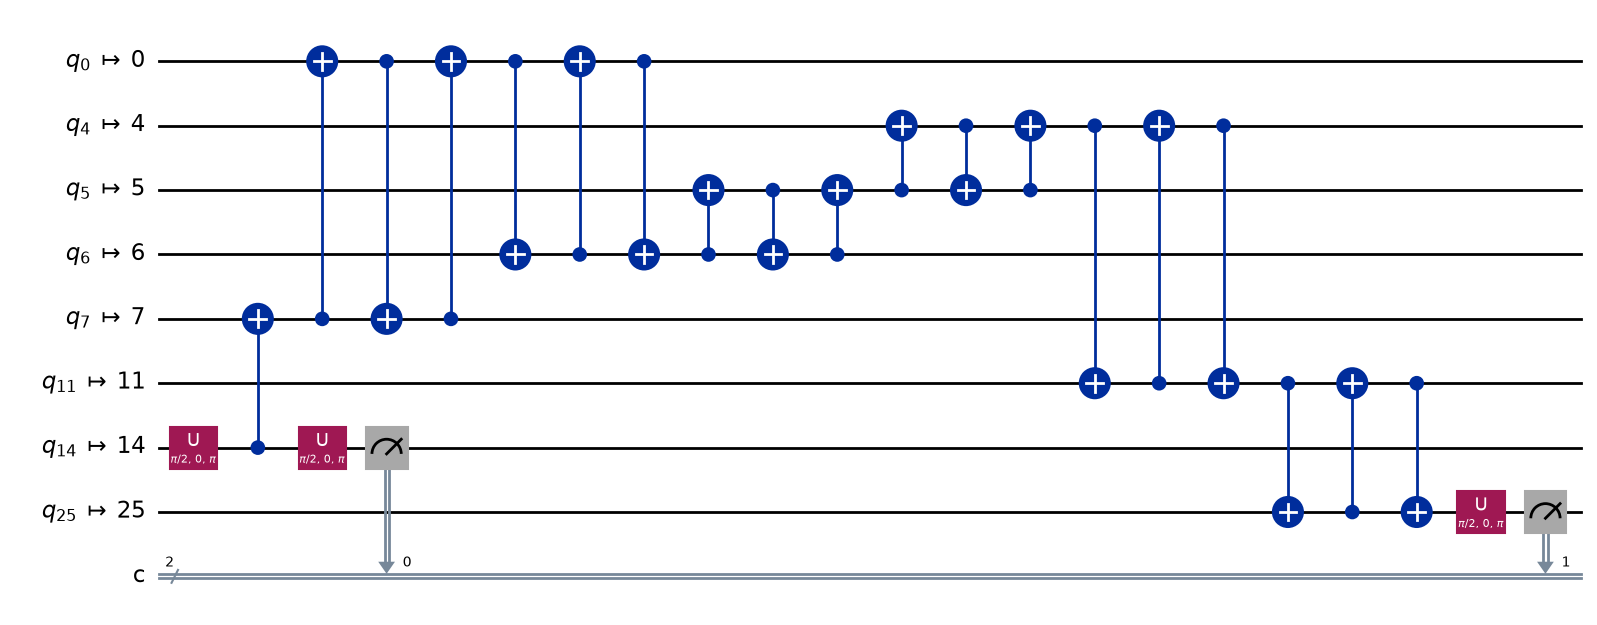

Hyperbolic-inspired YY compiled circuit


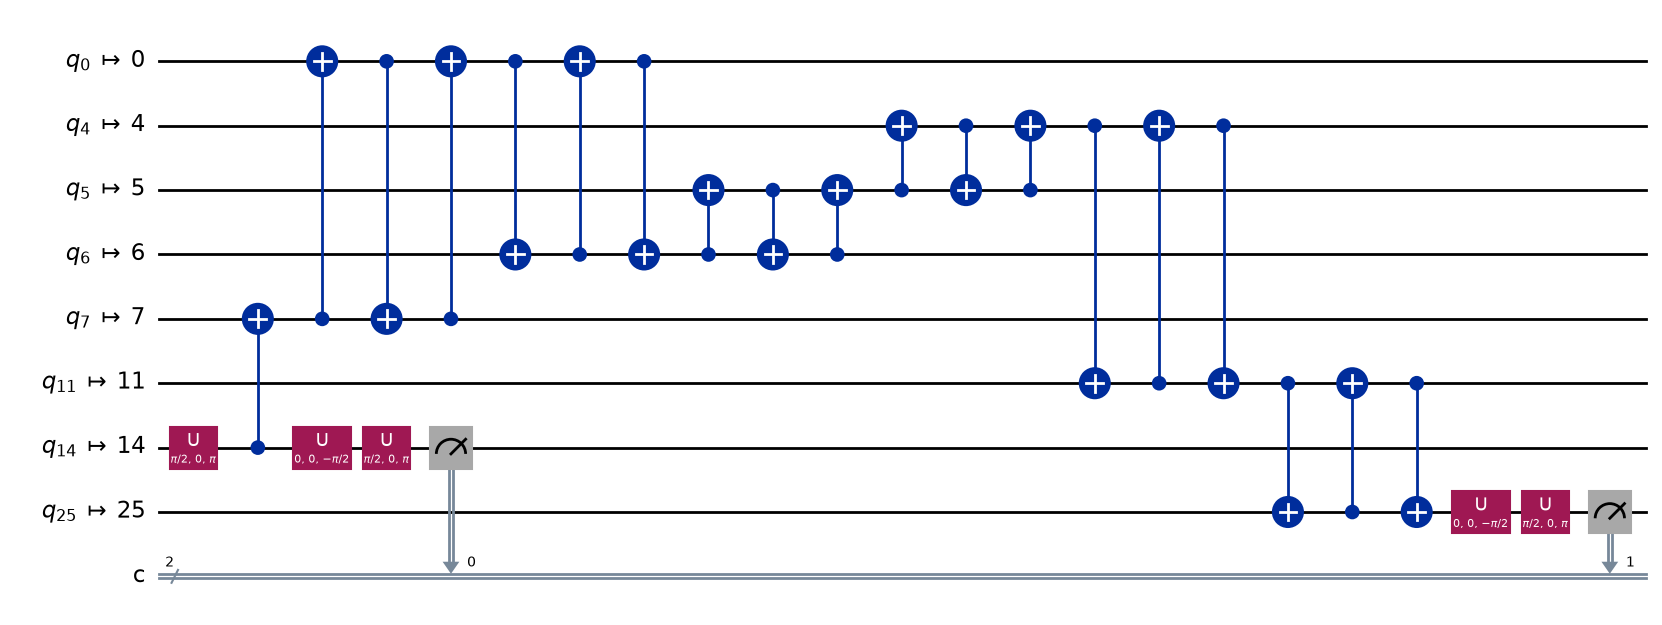

Hyperbolic-inspired ZZ compiled circuit


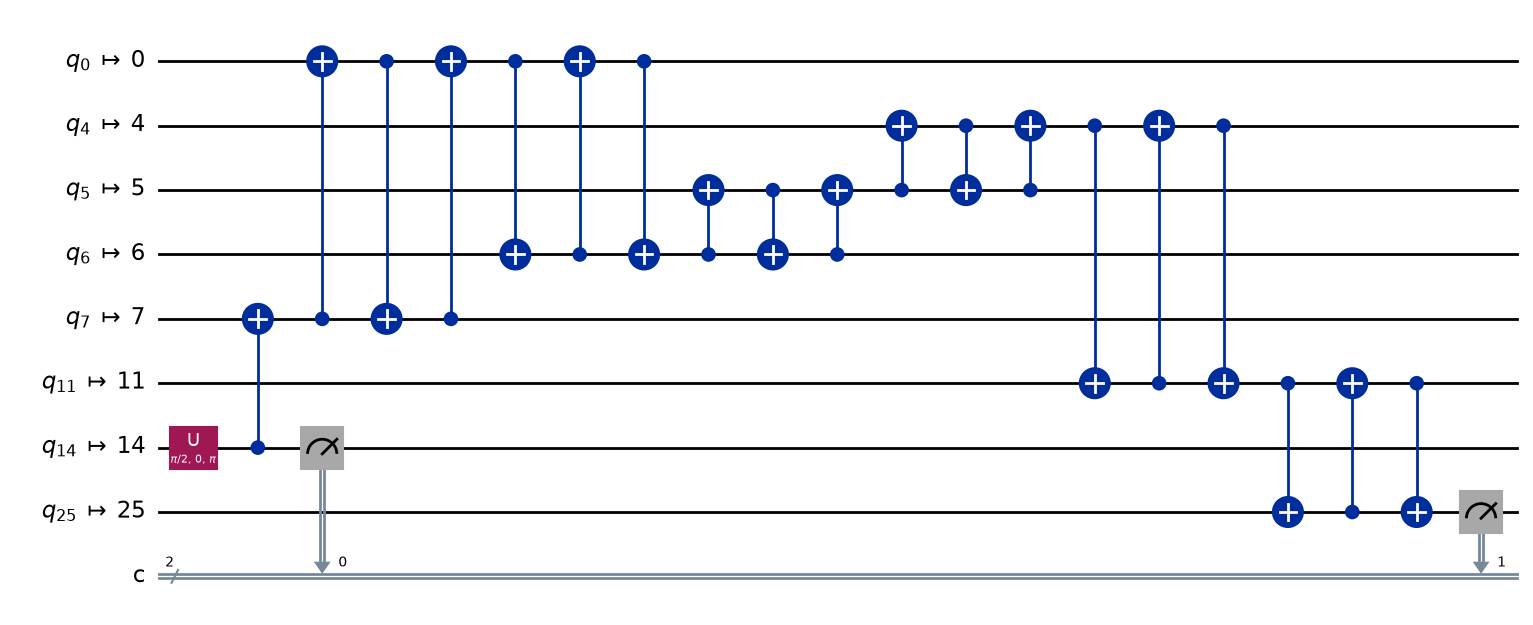

In [4]:
level2_routed_circuits, level2_native_circuits = {}, {}
for _, model_id, _ in LEVEL2_CASES:
    model = PROCESSORS[model_id]
    routed = {basis: level2_measurement_circuit(model_id, basis) for basis in BASIS_ORDER}

    # Compile synthetic circuits to u/cx and IBM circuits to the backend's native gates.
    # Aer uses these gate names to attach the configured noise channels.
    target = ({"backend": ibm_backend} if model_id == "ibm_today" else
              {"coupling_map": model.coupling_map(),
               "basis_gates": list(SYNTHETIC_BASIS_GATES)})
    native = {}
    for basis, circuit in routed.items():
        native[basis] = transpile(
            circuit, **target, initial_layout=list(range(model.num_qubits)),
            routing_method="none", optimization_level=OPTIMIZATION_LEVEL, seed_transpiler=SEED,
        )
        # The identity layout maps wire q to physical qubit q.
        # Verify directed gate edges and measurements at the two required physical ports.
        verify_level2_circuit(native[basis], model_id)
        print(model.name, basis, "compiled circuit")
        figure = native[basis].draw(output="mpl", fold=100, idle_wires=False)
        display(figure)
        plt.close(figure)
    level2_routed_circuits[model_id] = routed
    level2_native_circuits[model_id] = native

In [5]:
level2_results = {}
for case_number, model_id, _ in LEVEL2_CASES:
    model = PROCESSORS[model_id]
    noise = make_noise_model(model_id)
    simulator = AerSimulator(
        method=SIMULATOR_METHOD, noise_model=noise, **SIMULATOR_OPTIONS[model_id]
    )
    seeds = {basis: SEED + 100 * case_number + index
             for index, basis in enumerate(BASIS_ORDER)}
    counts, simulation_metadata = {}, {}
    for basis in BASIS_ORDER:
        # Apply the official noise model while sampling the stored native circuit.
        result = simulator.run(
            level2_native_circuits[model_id][basis], shots=SHOTS_PER_BASIS,
            seed_simulator=seeds[basis],
        ).result()
        assert result.success, result.status
        counts[basis] = result.get_counts()
        assert sum(counts[basis].values()) == SHOTS_PER_BASIS
        metadata = result.results[0].metadata
        assert metadata["method"] == SIMULATOR_METHOD
        simulation_metadata[basis] = {
            "Method": metadata["method"], "Active simulator qubits": metadata.get("num_qubits"),
        }
    settings = {
        "Case": case_number, "Processor": model_id, "Physical ports": model.ports,
        "Configuration version": CONFIG_VERSION, "Route": processor_routes[model_id],
        "Noise": "official model", "Simulator method": SIMULATOR_METHOD,
        "Simulator options": SIMULATOR_OPTIONS[model_id], "Simulator seeds": seeds,
        "Shots per basis": SHOTS_PER_BASIS, "Transpiler seed": SEED,
        "Initial layout": list(range(model.num_qubits)), "Routing method": "none",
        "Optimization level": OPTIMIZATION_LEVEL, "Bootstrap resamples": BOOTSTRAP_RESAMPLES,
        "Confidence level": CONFIDENCE_LEVEL, "Bootstrap seed": SEED + 100 * case_number + 10,
    }
    level2_results[case_number] = {
        "settings": settings, "counts": counts, "noise_model": noise,
        "simulation_metadata": simulation_metadata,
        "native_circuits": level2_native_circuits[model_id],
    }
    display(pd.Series(settings, name="Value").to_frame())
    display(noise)
    display(pd.DataFrame([
        {"Basis": basis, "Simulator seed": seeds[basis],
         **{word: counts[basis].get(word, 0) for word in ("00", "01", "10", "11")}}
        for basis in BASIS_ORDER
    ]))

,Value
Case,2
Processor,reference_2016
Physical ports,"(0, 3)"
Configuration version,1.0
Route,"[0, 1, 2, 3]"
Noise,official model
Simulator method,matrix_product_state
Simulator options,{}
Simulator seeds,"{'XX': 2226, 'YY': 2227, 'ZZ': 2228}"
Shots per basis,8192


<NoiseModel on ['cx', 'measure', 'u']>

,Basis,Simulator seed,00,01,10,11
0,XX,2226,3664,386,377,3765
1,YY,2227,388,3819,3605,380
2,ZZ,2228,3765,356,371,3700


,Value
Case,5
Processor,ibm_today
Physical ports,"(0, 15)"
Configuration version,1.0
Route,"[0, 1, 4, 7, 10, 12, 15]"
Noise,official model
Simulator method,matrix_product_state
Simulator options,"{'max_parallel_threads': 1, 'max_parallel_expe..."
Simulator seeds,"{'XX': 2526, 'YY': 2527, 'ZZ': 2528}"
Shots per basis,8192


<NoiseModel on ['measure', 'reset', 'sx', 'id', 'cx', 'x']>

,Basis,Simulator seed,00,01,10,11
0,XX,2526,3729,467,457,3539
1,YY,2527,479,3568,3695,450
2,ZZ,2528,3859,620,350,3363


,Value
Case,8
Processor,hyperbolic
Physical ports,"(14, 25)"
Configuration version,1.0
Route,"[14, 7, 0, 6, 5, 4, 11, 25]"
Noise,official model
Simulator method,matrix_product_state
Simulator options,{'max_parallel_threads': 1}
Simulator seeds,"{'XX': 2826, 'YY': 2827, 'ZZ': 2828}"
Shots per basis,8192


<NoiseModel on ['cx', 'measure', 'u']>

,Basis,Simulator seed,00,01,10,11
0,XX,2826,3383,735,755,3319
1,YY,2827,789,3314,3326,763
2,ZZ,2828,3372,745,722,3353


In [6]:
def level2_correlator(counts):
    shots = sum(counts.values())
    if shots <= 0:
        raise ValueError("A correlator needs at least one observed shot.")
    signed_total = 0
    for outcome, count in counts.items():
        # Qiskit prints c1c0. Reverse the string to read the port bits in c0, c1 order.
        bits = outcome.replace(" ", "")[::-1]
        signed_total += count if bits[0] == bits[1] else -count
    return signed_total / shots


def level2_fidelity(correlations):
    # Phi+ has correlations (+1, -1, +1), which fixes the minus sign on YY.
    return (1 + correlations["XX"] - correlations["YY"] + correlations["ZZ"]) / 4


def level2_fidelity_interval(counts_by_basis, resamples, confidence, seed):
    rng = np.random.default_rng(seed)
    resampled_correlations = {}
    for basis in BASIS_ORDER:
        shots = sum(counts_by_basis[basis].values())
        probability_agree = (1 + level2_correlator(counts_by_basis[basis])) / 2
        # Group the four outcomes by whether the two port bits agree.
        # Resample those group counts with a binomial draw.
        agreeing = rng.binomial(shots, probability_agree, size=resamples)
        resampled_correlations[basis] = 2 * agreeing / shots - 1
    # Combine the independently resampled XX, YY, and ZZ correlations into fidelities.
    fidelities = level2_fidelity(resampled_correlations)
    tail = (1 - confidence) / 2
    return tuple(float(bound) for bound in np.quantile(fidelities, [tail, 1 - tail]))


def level2_circuit_costs(native, routed):
    counted = RemoveBarriers()(native)
    touched = {counted.find_bit(qubit).index
               for instruction in counted.data for qubit in instruction.qubits}
    return {
        "Depth": counted.depth(),
        "Two-qubit gates": sum(len(instruction.qubits) == 2 for instruction in counted.data),
        # Count transport SWAPs in the routed circuit.
        # Native compilation expands each of them into three CX gates.
        "SWAPs": int(routed.count_ops().get("swap", 0)),
        "Physical qubits": len(touched),
    }


for case_number, model_id, _ in LEVEL2_CASES:
    result = level2_results[case_number]
    correlations = {basis: level2_correlator(counts) for basis, counts in result["counts"].items()}
    fidelity = level2_fidelity(correlations)
    interval = level2_fidelity_interval(
        result["counts"], BOOTSTRAP_RESAMPLES, CONFIDENCE_LEVEL, result["settings"]["Bootstrap seed"]
    )
    costs = {basis: level2_circuit_costs(
        result["native_circuits"][basis], level2_routed_circuits[model_id][basis]
    ) for basis in BASIS_ORDER}
    accounting = pd.DataFrame([
        {"Case": case_number, "Basis": basis, "Attempted": SHOTS_PER_BASIS,
         "Accepted": sum(result["counts"][basis].values()), "Discarded": 0, "Yield": 1.0}
        for basis in BASIS_ORDER
    ])
    # Level 2 accepts every attempted shot, so its reported yield is 1.
    summary = {
        "Case": case_number, "Processor model": PROCESSORS[model_id].name, "Level": 2,
        "F": fidelity, "95% CI": interval, **costs["ZZ"], "Yield": 1.0, "Discarded shots": 0,
    }
    result.update({"correlations": correlations, "costs": costs,
                   "shot_accounting": accounting, "summary": summary})
    display(pd.DataFrame([
        {"Case": case_number, "Basis": basis, "Correlation": correlations[basis], **costs[basis]}
        for basis in BASIS_ORDER
    ]))
    display(accounting)

level2_results_table = pd.DataFrame([result["summary"] for result in level2_results.values()])
display(level2_results_table)
display(pd.DataFrame([
    {"Case": case, "Fidelity loss from ideal target": 1 - result["summary"]["F"]}
    for case, result in level2_results.items()
]))

,Case,Basis,Correlation,Depth,Two-qubit gates,SWAPs,Physical qubits
0,2,XX,0.813721,10,7,2,4
1,2,YY,-0.812500,11,7,2,4
2,2,ZZ,0.822510,9,7,2,4


,Case,Basis,Attempted,Accepted,Discarded,Yield
0,2,XX,8192,8192,0,1.0
1,2,YY,8192,8192,0,1.0
2,2,ZZ,8192,8192,0,1.0


,Case,Basis,Correlation,Depth,Two-qubit gates,SWAPs,Physical qubits
0,5,XX,0.774414,23,16,5,7
1,5,YY,-0.773193,24,16,5,7
2,5,ZZ,0.763184,20,16,5,7


,Case,Basis,Attempted,Accepted,Discarded,Yield
0,5,XX,8192,8192,0,1.0
1,5,YY,8192,8192,0,1.0
2,5,ZZ,8192,8192,0,1.0


,Case,Basis,Correlation,Depth,Two-qubit gates,SWAPs,Physical qubits
0,8,XX,0.636230,22,19,6,8
1,8,YY,-0.621094,23,19,6,8
2,8,ZZ,0.641846,21,19,6,8


,Case,Basis,Attempted,Accepted,Discarded,Yield
0,8,XX,8192,8192,0,1.0
1,8,YY,8192,8192,0,1.0
2,8,ZZ,8192,8192,0,1.0


,Case,Processor model,Level,F,95% CI,Depth,Two-qubit gates,SWAPs,Physical qubits,Yield,Discarded shots
0,2,2016-inspired,2,0.862183,"(0.856566, 0.867432)",9,7,2,4,1.0,0
1,5,IBM-style today,2,0.827698,"(0.821716, 0.833557)",20,16,5,7,1.0,0
2,8,Hyperbolic-inspired,2,0.724792,"(0.717468, 0.731998)",21,19,6,8,1.0,0


,Case,Fidelity loss from ideal target
0,2,0.137817
1,5,0.172302
2,8,0.275208


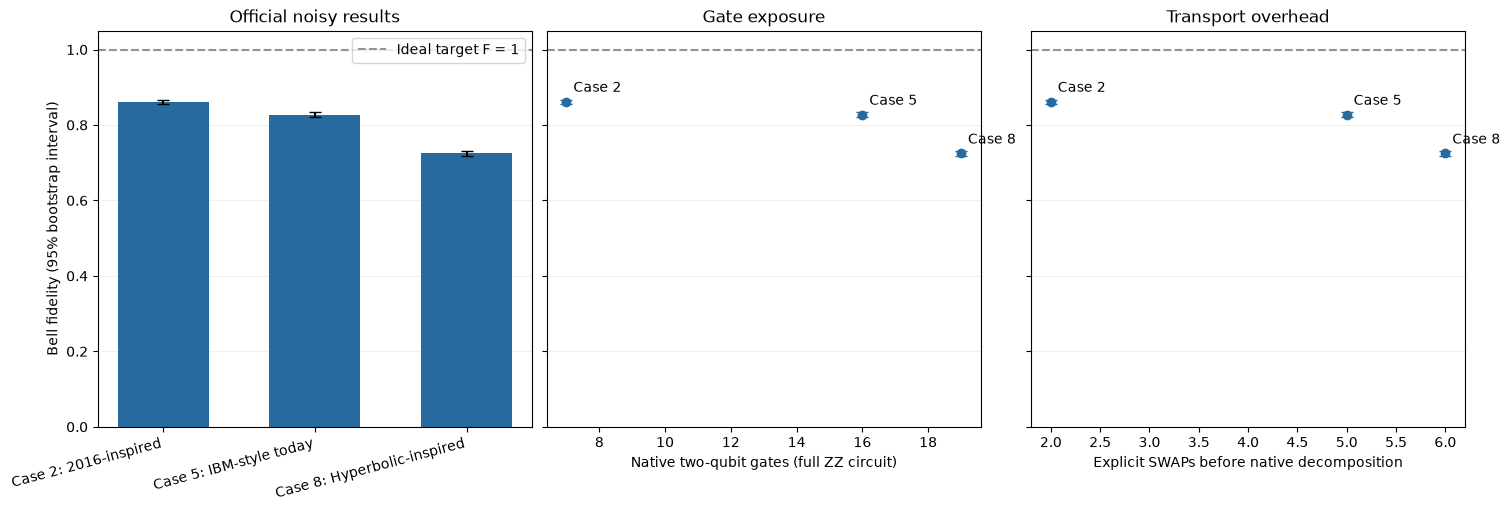

In [7]:
figure, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, layout="constrained")
for index, result in enumerate(level2_results.values()):
    summary = result["summary"]
    fidelity = summary["F"]
    lower, upper = summary["95% CI"]
    error = [[fidelity - lower], [upper - fidelity]]
    axes[0].bar(index, fidelity, width=0.6, color="#276b9e")
    axes[0].errorbar(index, fidelity, yerr=error, fmt="none", color="black", capsize=4)
    for axis, metric in zip(axes[1:], ("Two-qubit gates", "SWAPs")):
        axis.errorbar(summary[metric], fidelity, yerr=error, fmt="o", color="#276b9e", capsize=4)
        axis.annotate(f"Case {summary['Case']}", (summary[metric], fidelity),
                      xytext=(5, 7), textcoords="offset points")
# Phi+ has unit fidelity, so draw F = 1 as the reference line.
for axis in axes:
    axis.axhline(1, color="#8f9399", linestyle="--", label="Ideal target F = 1")
    axis.set_ylim(0, 1.05)
    axis.grid(axis="y", alpha=0.2)
    axis.set_axisbelow(True)
axes[0].set_xticks(range(len(level2_results)),
                   [f"Case {row['Case']}: {row['Processor model']}"
                    for row in level2_results_table.to_dict("records")], rotation=15, ha="right")
axes[0].set_ylabel("Bell fidelity (95% bootstrap interval)")
axes[0].set_title("Official noisy results")
axes[0].legend()
axes[1].set_xlabel("Native two-qubit gates (full ZZ circuit)")
axes[1].set_title("Gate exposure")
axes[2].set_xlabel("Explicit SWAPs before native decomposition")
axes[2].set_title("Transport overhead")
# Cases 2 and 8 share u/cx noise parameters; each extra SWAP adds three noisy CX gates.
# IBM's points include its calibrated gate errors and qubit-specific readout errors.
display(figure)
plt.close(figure)

## Level 3 — Protect it: detect errors

**Cases 3, 6, 9:** implement one justified protection or error-detection check on each model. Explain which faults it detects, which it misses, ancilla placement and routing, and the acceptance rule. Use the same protection procedure and acceptance rule before the basis rotations in all three bases. Do not postselect using final port outcomes.

Compare conditional fidelity and its 95% interval with Level 2. Report acceptance fraction, accepted and discarded shots (per basis), extra gates, depth and physical qubits including ancillas. Handle zero accepted shots explicitly; do not report a fabricated fidelity. Discuss whether any improvement justifies its overhead and lost shots. An accurately analyzed lack of improvement is a valid result.


In [ ]:
# TODO: Write your solution here.


## Nine-case results

Replace every TODO with measured results. Fidelity is conditional on acceptance for Level 3. Report yield and discarded shots for all cases, including cases without postselection. Use the complete compiled ZZ circuit for table costs, following the README common reporting conventions. Provide XX and YY costs separately. Table yield is total accepted shots across all three bases divided by total attempted shots; discarded shots is the sum across bases. Report attempted, accepted and discarded shots per basis below the table. Cases without postselection have yield 1 and zero discarded shots.

| Case | Processor model | Level | F | 95% CI | Depth | Two-qubit gates | SWAPs | Physical qubits | Yield | Discarded shots |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 2016-inspired | 1 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 2 | 2016-inspired | 2 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 3 | 2016-inspired | 3 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 4 | IBM-style today | 1 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 5 | IBM-style today | 2 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 6 | IBM-style today | 3 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 7 | Hyperbolic-inspired | 1 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 8 | Hyperbolic-inspired | 2 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 9 | Hyperbolic-inspired | 3 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |


In [ ]:
# TODO: Assemble your measured results and comparison plots.


## Scientific interpretation and recommendation

Explain the fidelity changes using compiled operations and noise assumptions. Compare protection overhead and yield across models. State the limits of conclusions drawn from finite graphs and different noise models. Recommend one hardware or software design choice for future cloud systems, supported by your results.

TODO: Write your interpretation and recommendation.

## Optional extensions — Levels 4–5

Keep alternative models, optimization studies, scaling studies and real QPU results separate from the nine official cases.

TODO (optional).

## Submission checklist

- Complete all nine cases with reproducible code and saved outputs.
- Include the three labeled coupling graphs, fixed ports and transpiled circuits.
- Report fidelity with uncertainty, circuit costs, physical qubits and postselection statistics.
- Record assumptions, package versions, shots, seeds and compilation/bootstrap settings.
- Include scientific interpretation and an evidence-backed design recommendation.
- Restart the kernel and run all cells from top to bottom before saving.
- Commit and push the notebook, supporting files and any dependency changes to your fork.
- Open a pull request to the main challenge repository by Sunday 4:00 PM, titled `Submission: <team name>`. Include team members, the notebook path, the results commit hash and reproduction steps, following the README submission instructions. Leave it open for organizer review.
